## MatLab Results

In [1]:
from __future__ import annotations
import numpy as np
import pandas as pd
from pathlib import Path
import re
import itertools
import more_itertools
from typing import NamedTuple


In [3]:
from own_itertools import iter_match_on_file
from Plot_template import RPlot, FigManager
RPlot.init_rcparams()
FM = FigManager()

## Load data

In [17]:
labels = ["e_aq", "O2", "H2O2", "OH_r", "H_r", "H2", "O2_r_minus", "R_r", "ROO_r"]
class DataFile(NamedTuple):
    O2: int
    TD: int
    DR: int
    data: pd.DataFrame
    
    @classmethod
    def from_regex(cls, reg:re.Match) -> DataFile:
        return cls(O2=int(reg.group("O2")),
                   TD=int(reg.group("total_dose")),
                   DR=int(reg.group("dose_rate")),
                   data=pd.read_csv(reg.string, index_col=0, header=0, names=labels),
                  )

In [30]:
folder = Path(r"C:\Users\rtonneau\DEV\MatLab\radioBioModel\data\PROTONS")
reg = re.compile(r".*proton__O2__(?P<O2>\d+)__TD__(?P<total_dose>\d+)__DR__(?P<dose_rate>\d+).csv")
files = [DataFile.from_regex(file) for file in iter_match_on_file(reg, folder.iterdir())]


## Plot for 1000 Gy/s

In [114]:
save_folder = Path(r"C:\Users\rtonneau\OneDrive - Université de Namur\Documents\EPT\MEETINGS\20230331\FIGURES\DR_1000")

### Species = ROO_r

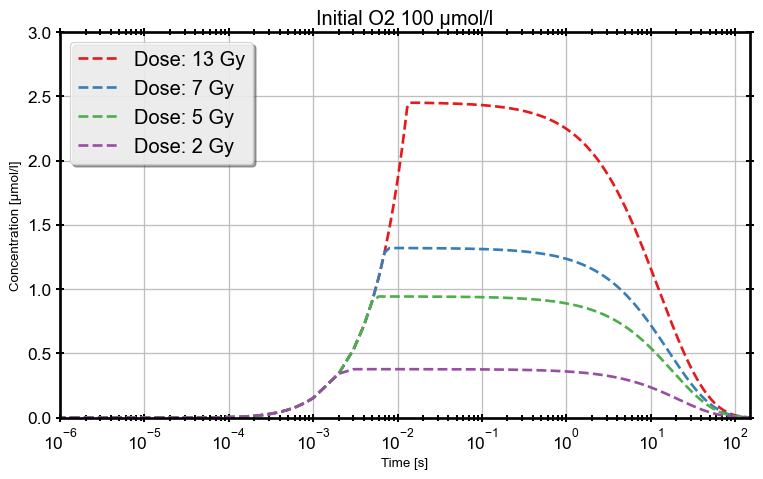

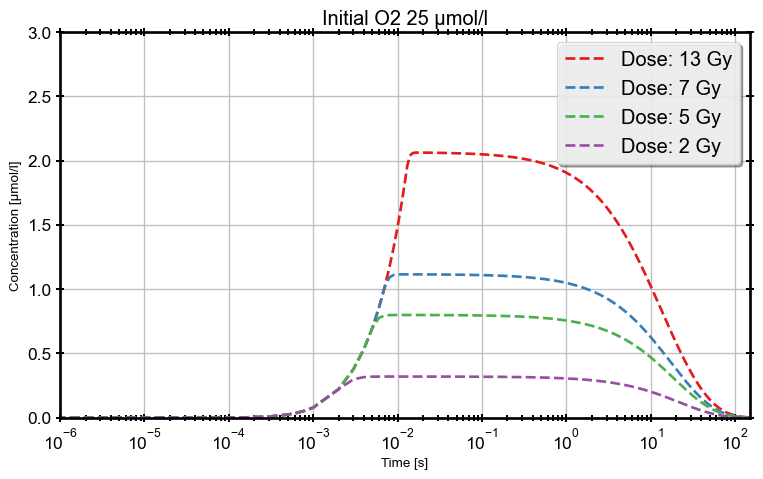

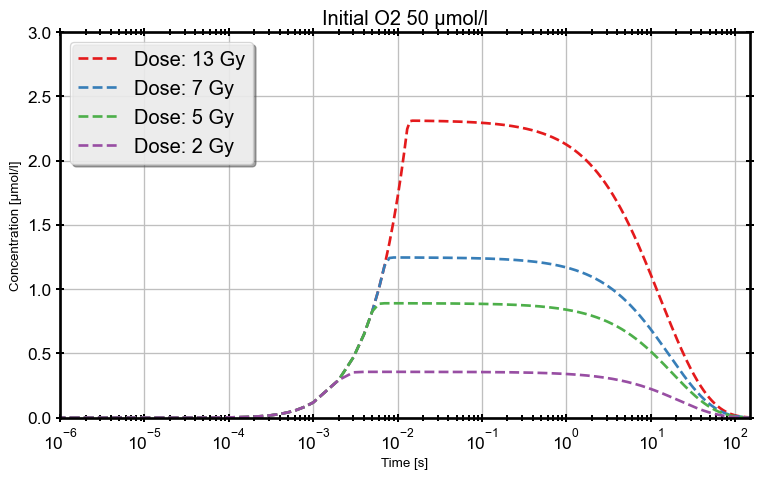

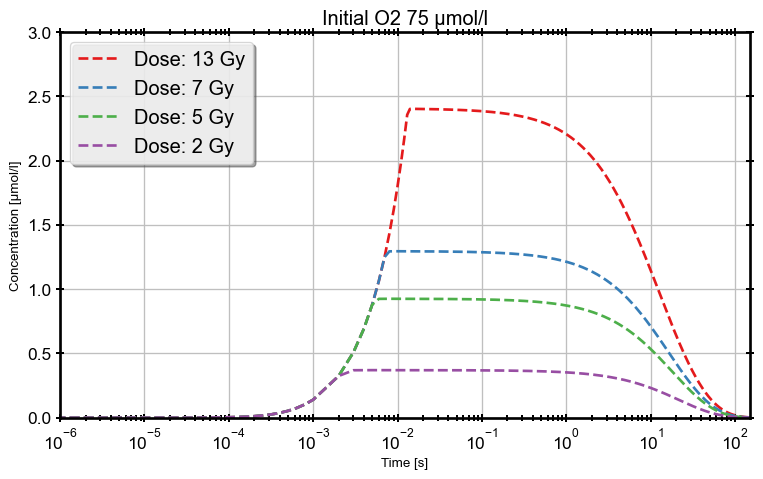

In [79]:
buckets = more_itertools.bucket(filter(lambda x: x.TD<15 and x.DR==1e3, files), key=lambda x: x.O2)
for O2 in buckets:
    title = f"O2 {O2}"
    with FM.open(title) as (fig, ax):
        for data_file in sorted(buckets[O2], key=lambda x: x.TD, reverse=True):
            df = data_file.data
            ax.semilogx(df.index, df["ROO_r"], label=f"Dose: {data_file.TD:.0f} Gy", marker="")
        ax.legend()
        ax.set_xlim([1e-6, 150])
        ax.set_ylim([0, 3])
        ax.set_title(f"Initial O2 {O2} µmol/l")
        ax.set_xlabel("Time [s]")
        ax.set_ylabel("Concentration [µmol/l]")
        if save_folder.exists():
            fig.savefig(save_folder / f"cc_ROOr_O2_{O2}.png")

### Species = R_r

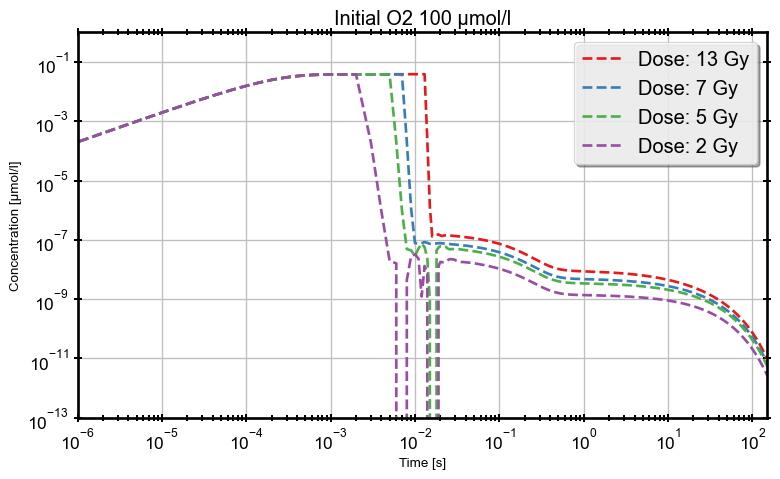

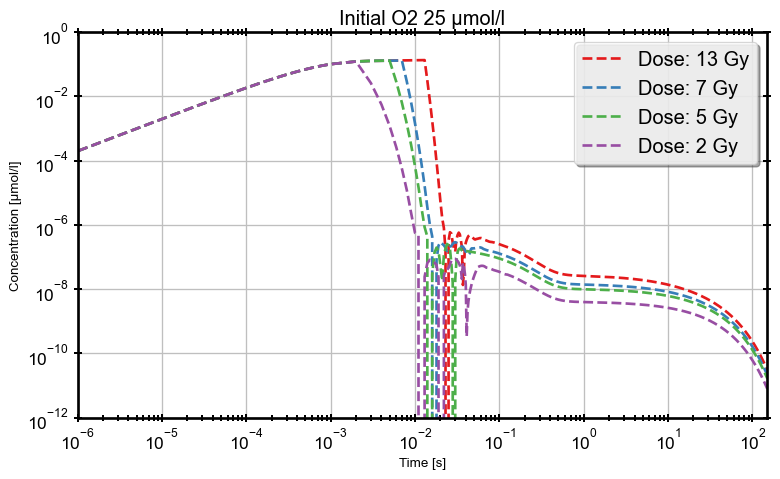

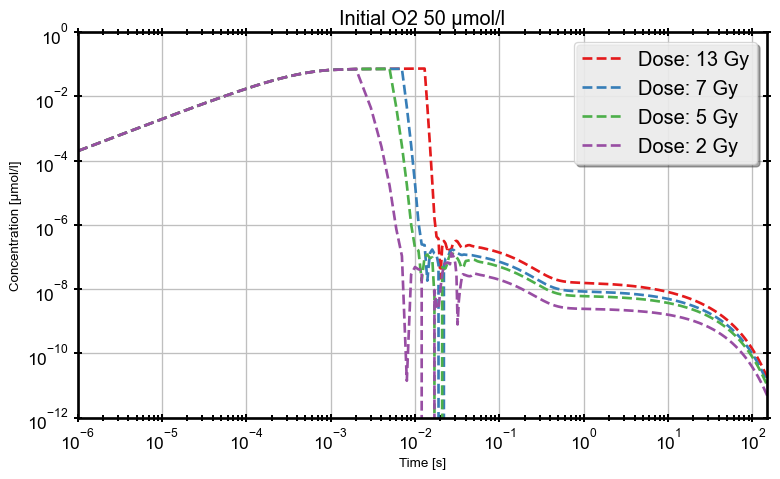

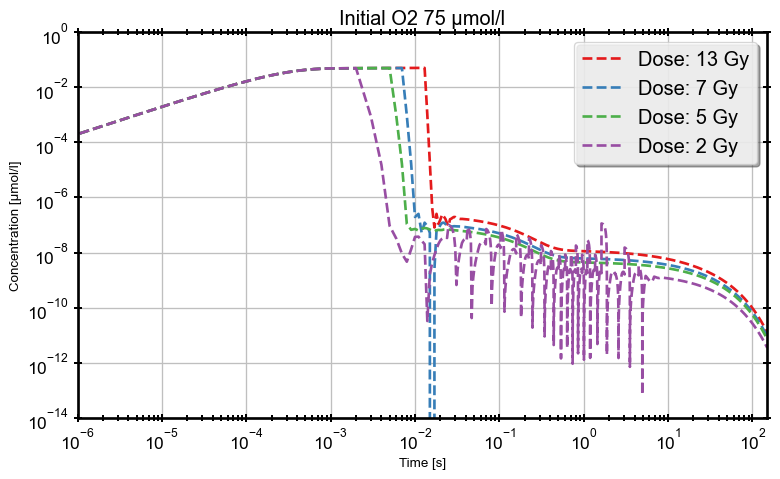

In [115]:
buckets = more_itertools.bucket(filter(lambda x: x.TD<15 and x.DR==1e3, files), key=lambda x: x.O2)
for O2 in buckets:
    with FM.open(f"O2 {O2}") as (fig, ax):
        for data_file in sorted(buckets[O2], key=lambda x: x.TD, reverse=True):
            df = data_file.data
            ax.loglog(df.index, df["R_r"], label=f"Dose: {data_file.TD:.0f} Gy", marker="")
        ax.legend()
        ax.set_xlim([1e-6, 150])
        #ax.set_ylim([1e-6, 10])
        ax.set_title(f"Initial O2 {O2} µmol/l")
        ax.set_xlabel("Time [s]")
        ax.set_ylabel("Concentration [µmol/l]")
        if save_folder.exists():
            fig.savefig(save_folder / f"cc_Rr_O2_{O2}.png")

### Integral of R_r

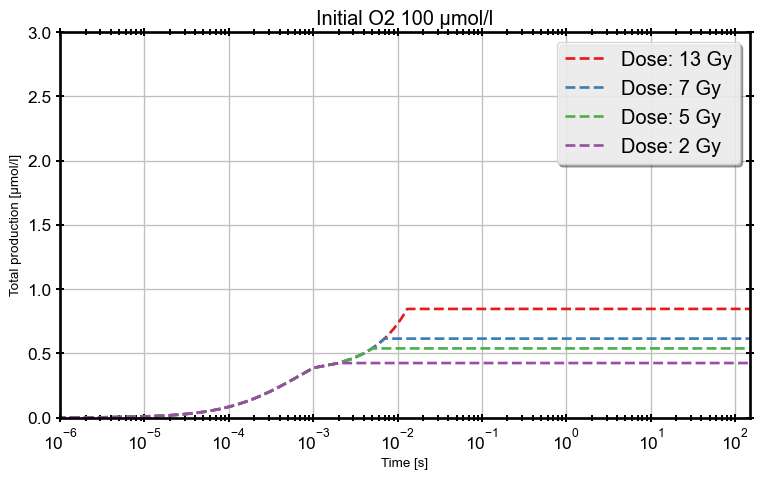

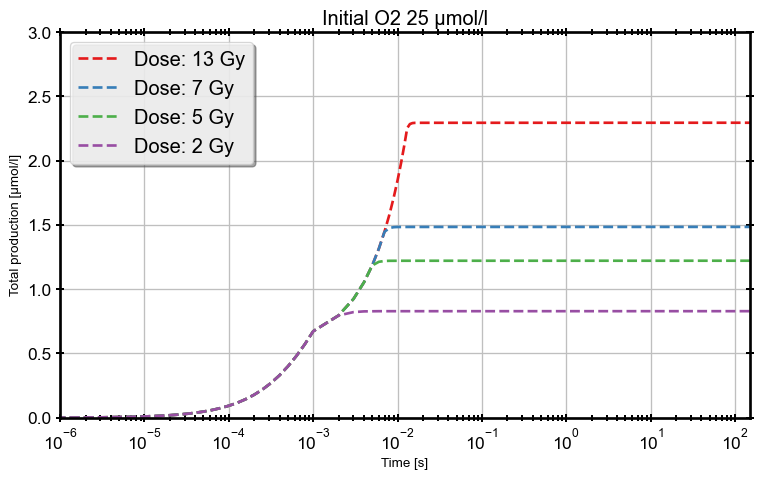

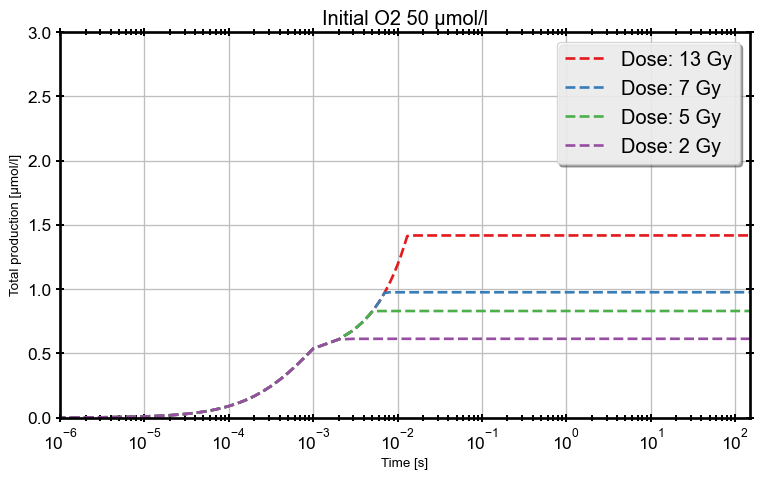

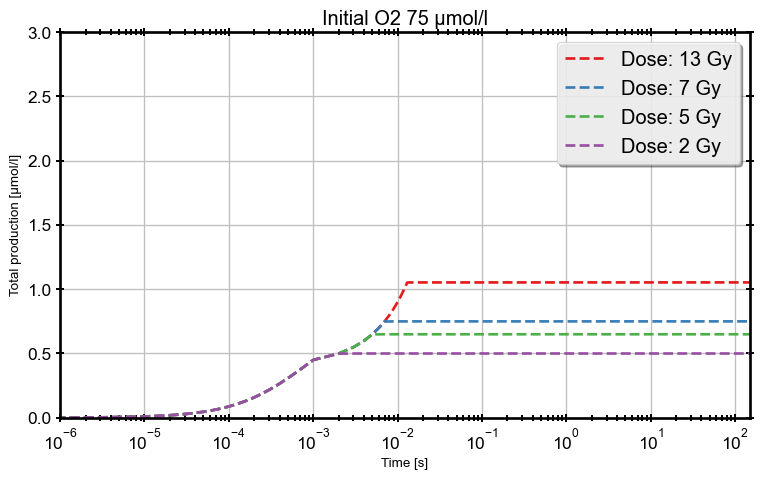

In [77]:
buckets = more_itertools.bucket(filter(lambda x: x.TD<15 and x.DR==1e3, files), key=lambda x: x.O2)
for O2 in buckets:
    with FM.open(f"O2 {O2}") as (fig, ax):
        for data_file in sorted(buckets[O2], key=lambda x: x.TD, reverse=True):
            df = data_file.data
            ax.semilogx(df.index, df["R_r"].cumsum(), label=f"Dose: {data_file.TD:.0f} Gy", marker="")
        ax.legend()
        ax.set_xlim([1e-6, 150])
        ax.set_ylim([0, 3])
        ax.set_title(f"Initial O2 {O2} µmol/l")
        ax.set_xlabel("Time [s]")
        ax.set_ylabel("Total production [µmol/l]")
        if save_folder.exists():
            fig.savefig(save_folder / f"integral_Rr_O2_{O2}.png")

### Species = O2

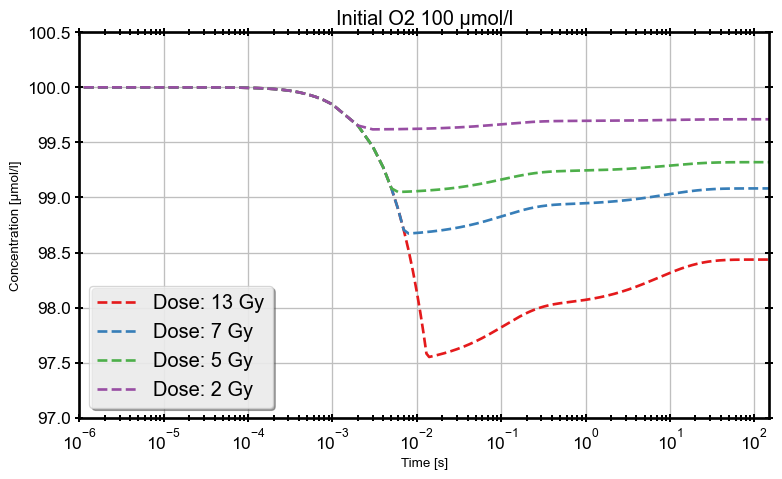

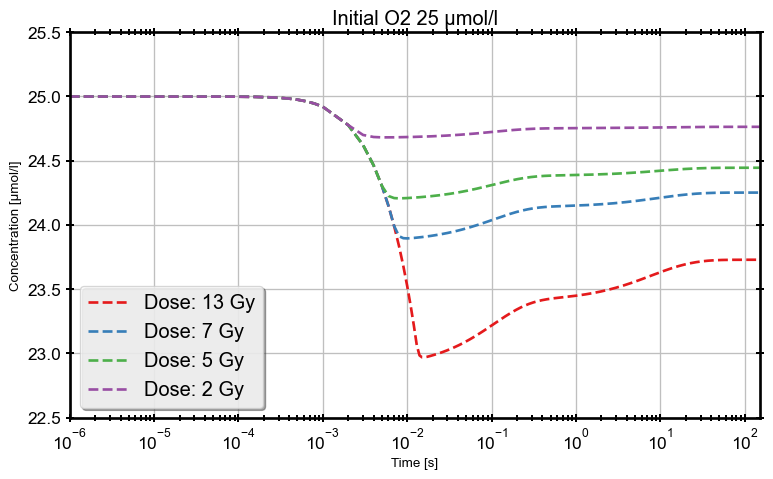

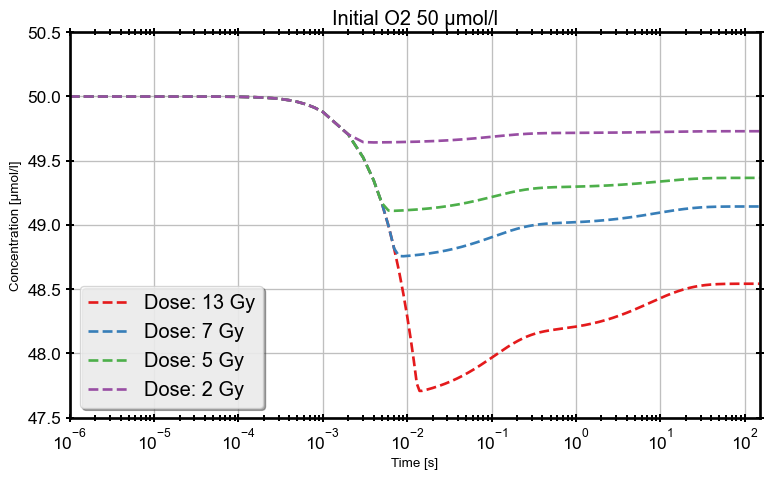

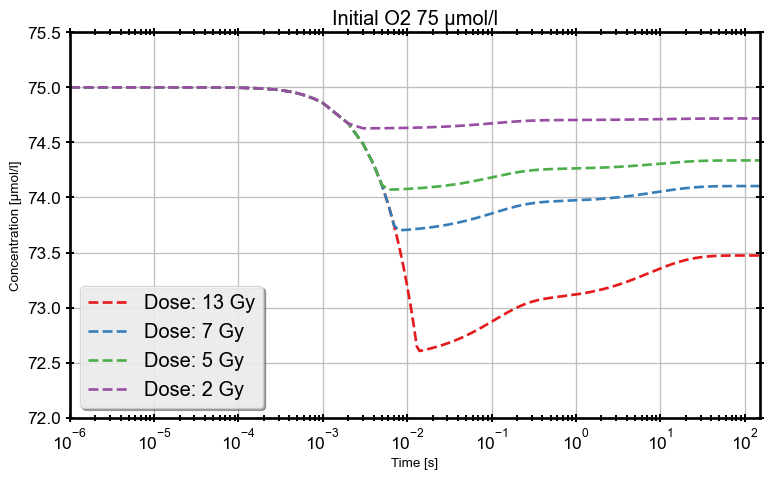

In [76]:
buckets = more_itertools.bucket(filter(lambda x: x.TD<15 and x.DR==1e3, files), key=lambda x: x.O2)
for O2 in buckets:
    with FM.open(f"O2 {O2}") as (fig, ax):
        for data_file in sorted(buckets[O2], key=lambda x: x.TD, reverse=True):
            df = data_file.data
            ax.semilogx(df.index, df["O2"], label=f"Dose: {data_file.TD:.0f} Gy", marker="")
        ax.legend()
        ax.set_xlim([1e-6, 150])
        #ax.set_ylim([1e-6, 10])
        ax.set_title(f"Initial O2 {O2} µmol/l")
        ax.set_xlabel("Time [s]")
        ax.set_ylabel("Concentration [µmol/l]")
        if save_folder.exists():
            fig.savefig(save_folder / f"cc_O2_O2_{O2}.png")

### Species = H2O2

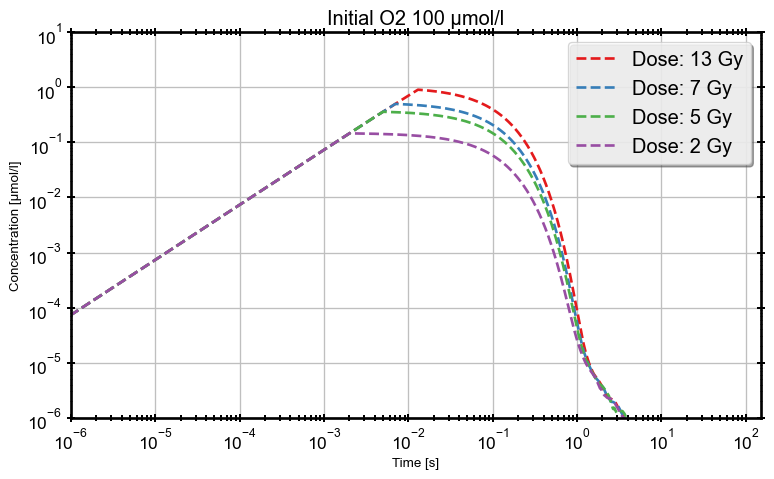

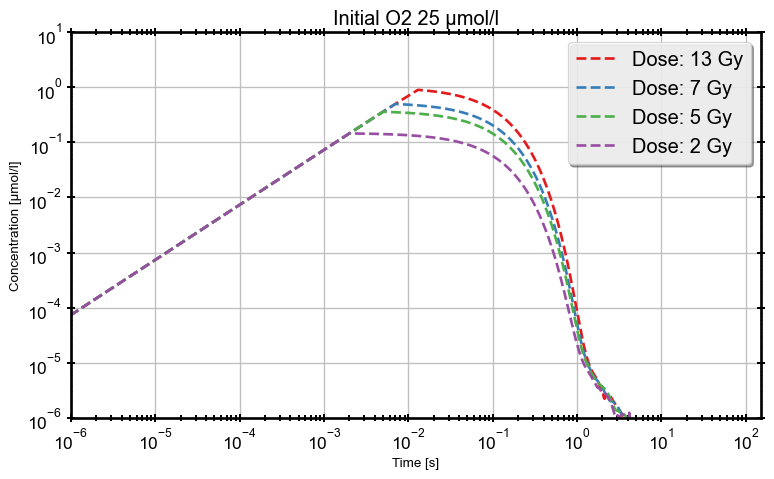

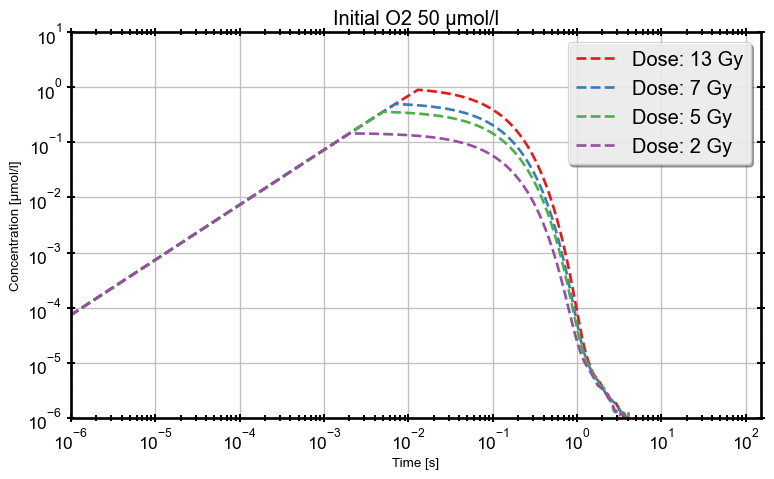

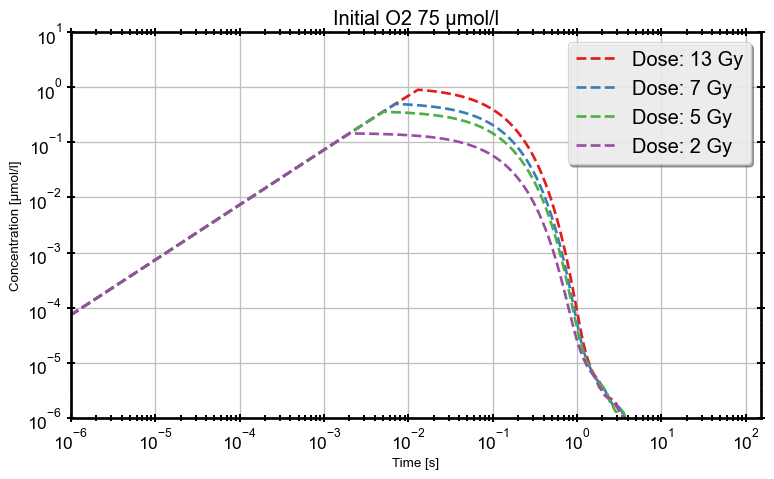

In [75]:
buckets = more_itertools.bucket(filter(lambda x: x.TD<15 and x.DR==1e3, files), key=lambda x: x.O2)
for O2 in buckets:
    with FM.open(f"O2 {O2}") as (fig, ax):
        for data_file in sorted(buckets[O2], key=lambda x: x.TD, reverse=True):
            df = data_file.data
            ax.loglog(df.index, df["H2O2"], label=f"Dose: {data_file.TD:.0f} Gy", marker="")
        ax.legend()
        ax.set_xlim([1e-6, 150])
        ax.set_ylim([1e-6, 10])
        ax.set_title(f"Initial O2 {O2} µmol/l")
        ax.set_xlabel("Time [s]")
        ax.set_ylabel("Concentration [µmol/l]")
        if save_folder.exists():
            fig.savefig(save_folder / f"cc_H2O2_O2_{O2}.png")

### Intergal values

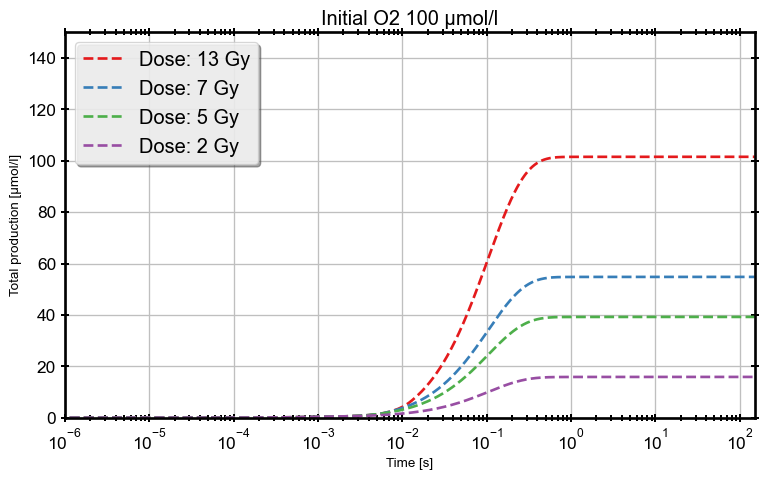

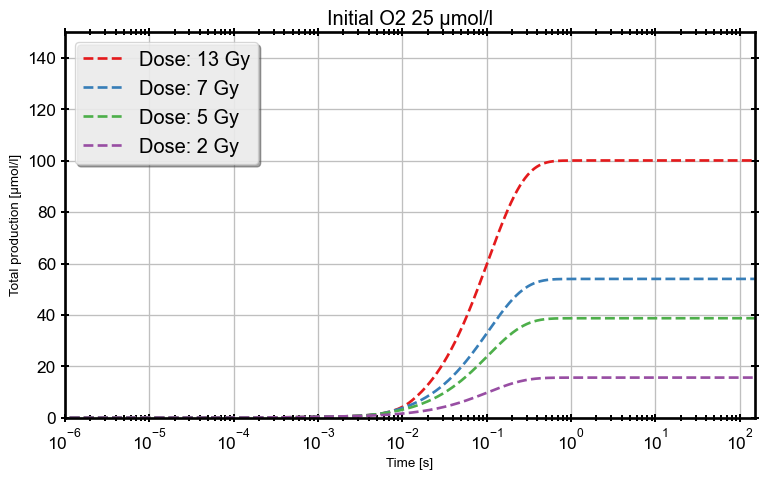

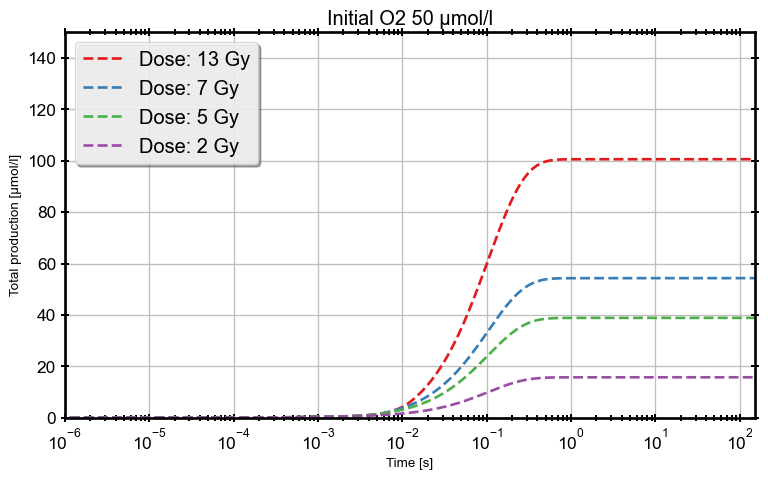

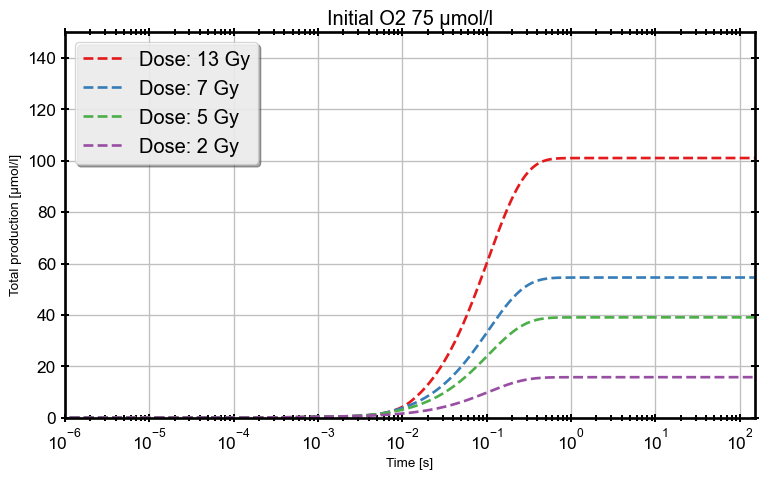

In [74]:
buckets = more_itertools.bucket(filter(lambda x: x.TD<15 and x.DR==1e3, files), key=lambda x: x.O2)
for O2 in buckets:
    with FM.open(f"O2 {O2}") as (fig, ax):
        for data_file in sorted(buckets[O2], key=lambda x: x.TD, reverse=True):
            df = data_file.data
            ax.semilogx(df.index, df["H2O2"].cumsum(), label=f"Dose: {data_file.TD:.0f} Gy", marker="")
        ax.legend()
        ax.set_xlim([1e-6, 150])
        ax.set_ylim([0, 150])
        ax.set_title(f"Initial O2 {O2} µmol/l")
        ax.set_xlabel("Time [s]")
        ax.set_ylabel("Total production [µmol/l]")
        if save_folder.exists():
            fig.savefig(save_folder / f"integral_H2O2_O2_{O2}.png")

## Plot for 100 Gy/s

In [80]:
save_folder = Path(r"C:\Users\rtonneau\OneDrive - Université de Namur\Documents\EPT\MEETINGS\20230331\FIGURES\DR_100")

### Species = ROO_r

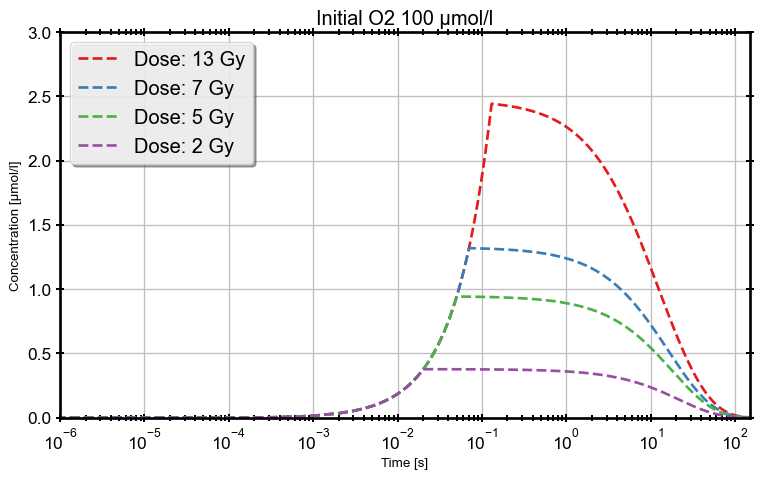

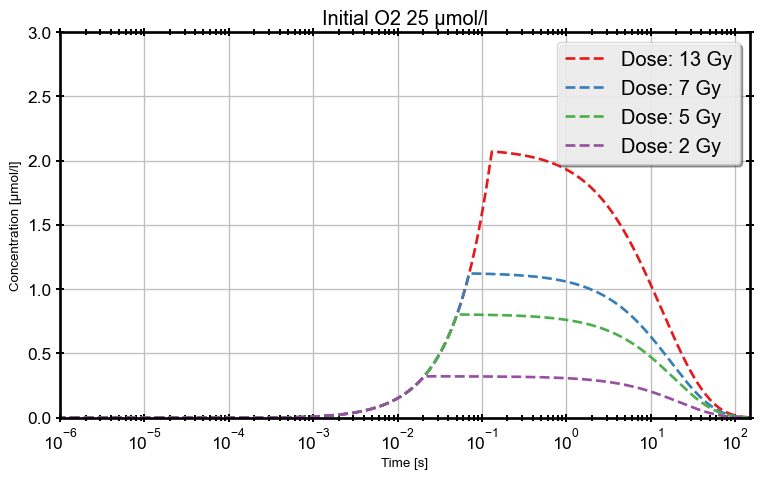

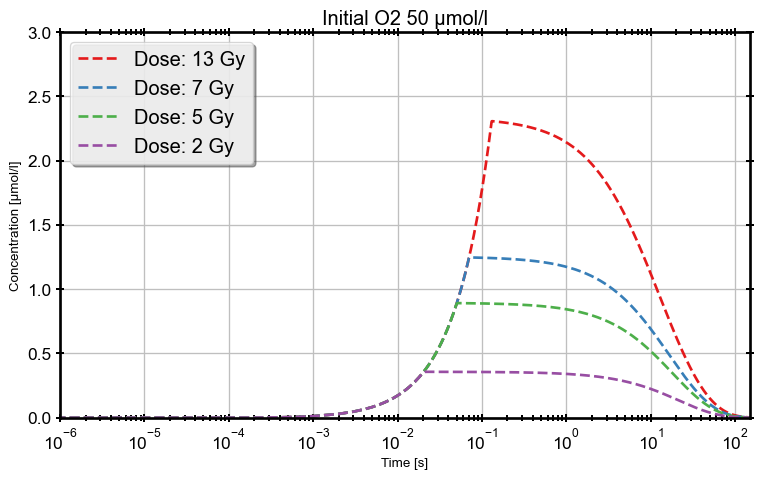

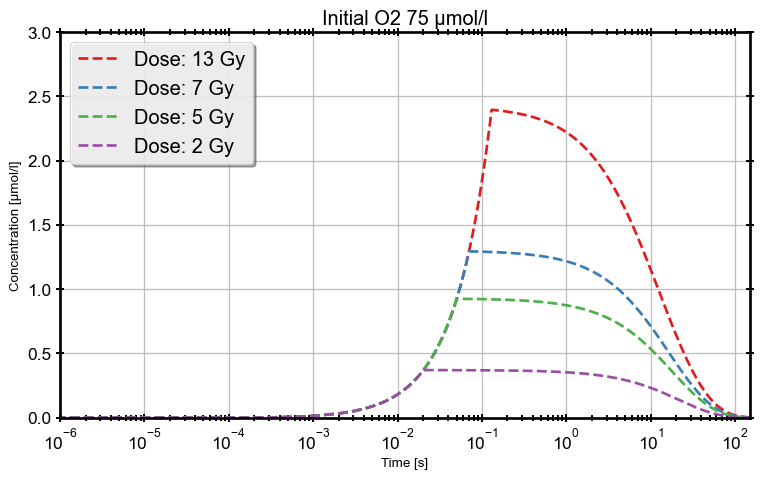

In [99]:
buckets = more_itertools.bucket(filter(lambda x: x.TD<15 and x.DR==1e2, files), key=lambda x: x.O2)
for O2 in buckets:
    title = f"O2 {O2}"
    with FM.open(title) as (fig, ax):
        for data_file in sorted(buckets[O2], key=lambda x: x.TD, reverse=True):
            df = data_file.data
            ax.semilogx(df.index, df["ROO_r"], label=f"Dose: {data_file.TD:.0f} Gy", marker="")
        ax.legend()
        ax.set_xlim([1e-6, 150])
        ax.set_ylim([0, 3])
        ax.set_title(f"Initial O2 {O2} µmol/l")
        ax.set_xlabel("Time [s]")
        ax.set_ylabel("Concentration [µmol/l]")
        if save_folder.exists():
            fig.savefig(save_folder / f"cc_ROOr_O2_{O2}.png")

### Integral of ROO_r

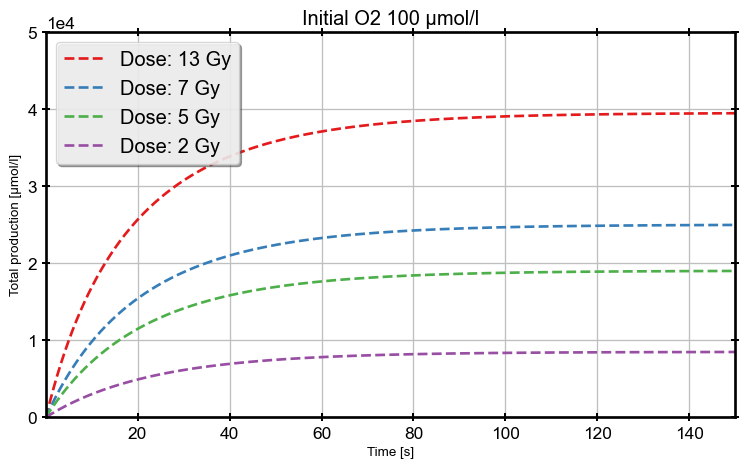

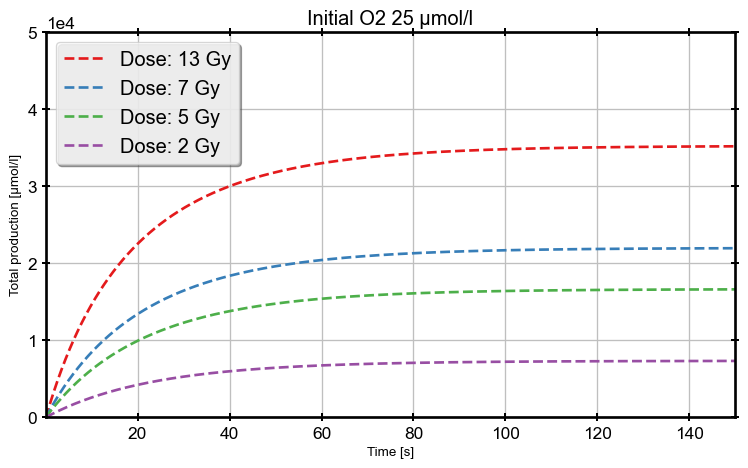

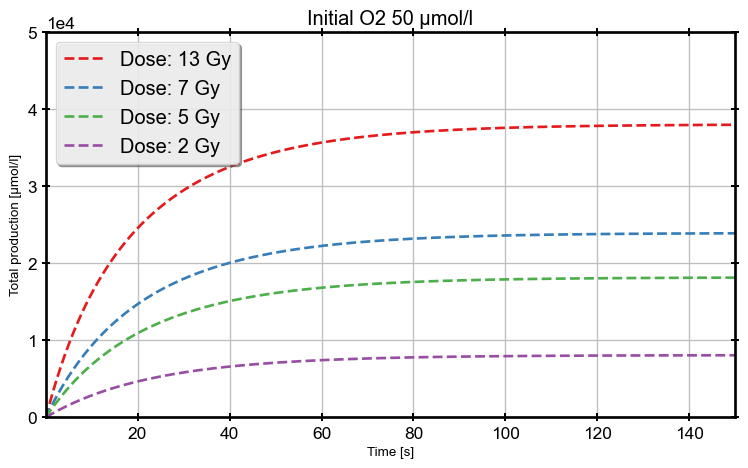

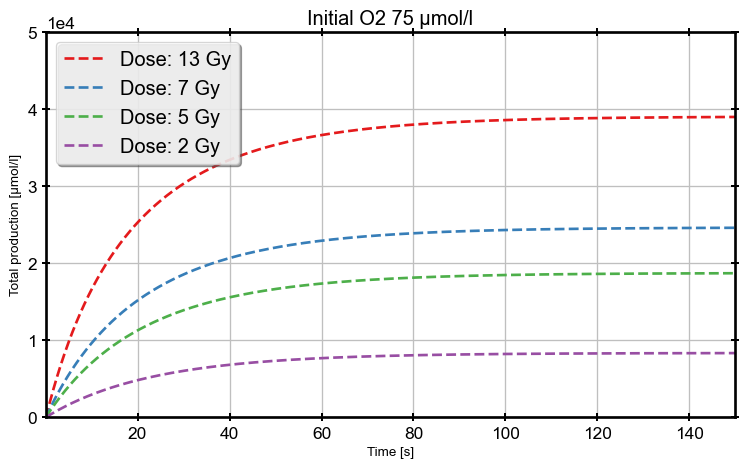

In [95]:
buckets = more_itertools.bucket(filter(lambda x: x.TD<15 and x.DR==1e2, files), key=lambda x: x.O2)
for O2 in buckets:
    with FM.open(f"O2 {O2}") as (fig, ax):
        for data_file in sorted(buckets[O2], key=lambda x: x.TD, reverse=True):
            df = data_file.data
            ax.plot(df.index, df["ROO_r"].cumsum(), label=f"Dose: {data_file.TD:.0f} Gy", marker="")
        ax.legend()
        ax.set_xlim([1e-6, 150])
        ax.set_ylim([0, 5e4])
        ax.set_title(f"Initial O2 {O2} µmol/l")
        ax.set_xlabel("Time [s]")
        ax.set_ylabel("Total production [µmol/l]")
        if save_folder.exists():
            fig.savefig(save_folder / f"integral_ROOr_O2_{O2}.png")

### Species = R_r

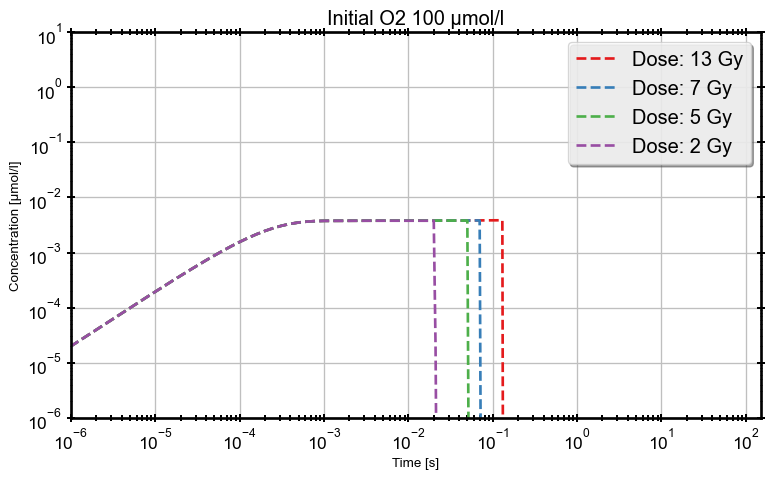

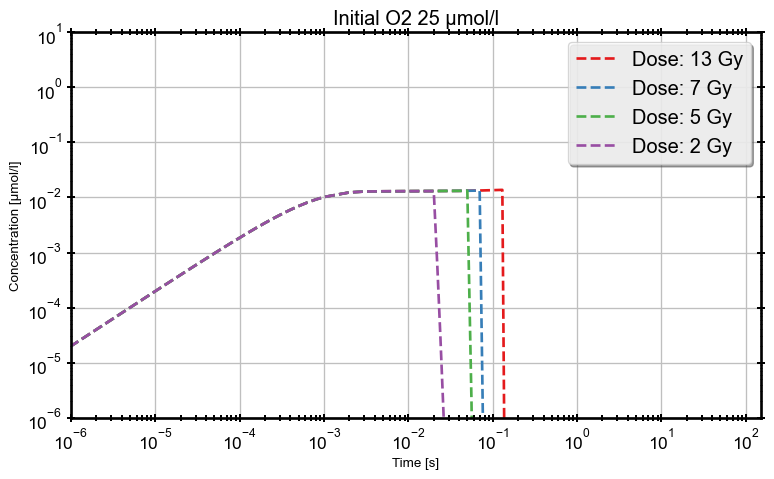

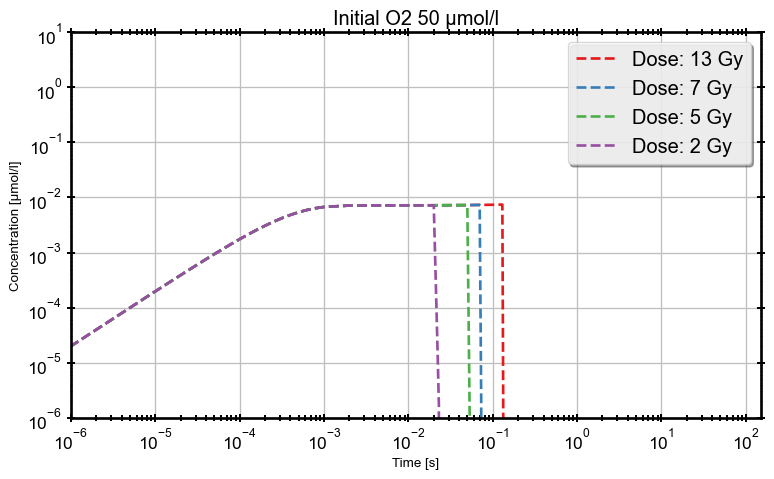

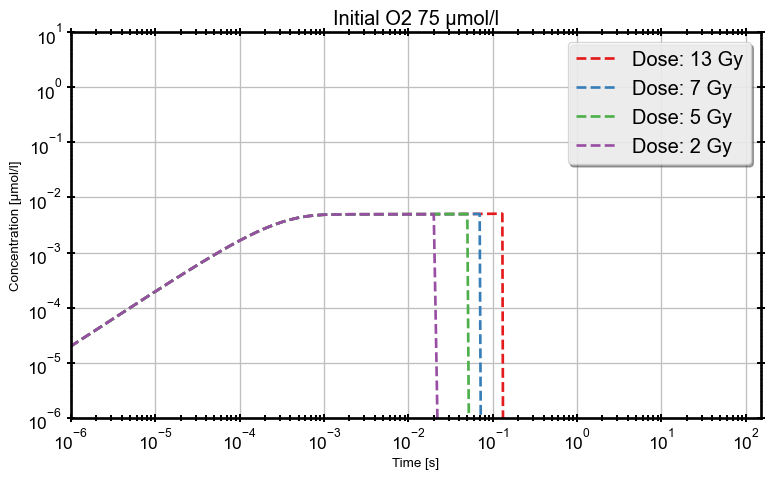

In [82]:
buckets = more_itertools.bucket(filter(lambda x: x.TD<15 and x.DR==1e2, files), key=lambda x: x.O2)
for O2 in buckets:
    with FM.open(f"O2 {O2}") as (fig, ax):
        for data_file in sorted(buckets[O2], key=lambda x: x.TD, reverse=True):
            df = data_file.data
            ax.loglog(df.index, df["R_r"], label=f"Dose: {data_file.TD:.0f} Gy", marker="")
        ax.legend()
        ax.set_xlim([1e-6, 150])
        ax.set_ylim([1e-6, 10])
        ax.set_title(f"Initial O2 {O2} µmol/l")
        ax.set_xlabel("Time [s]")
        ax.set_ylabel("Concentration [µmol/l]")
        if save_folder.exists():
            fig.savefig(save_folder / f"cc_Rr_O2_{O2}.png")

### Integral of R_r

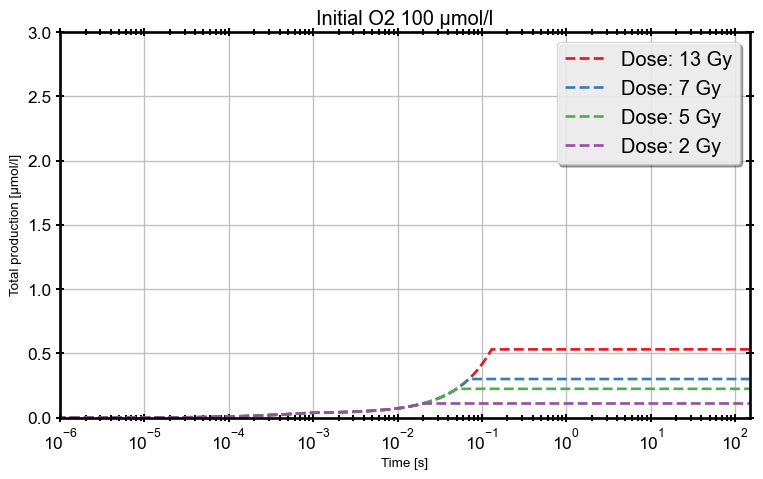

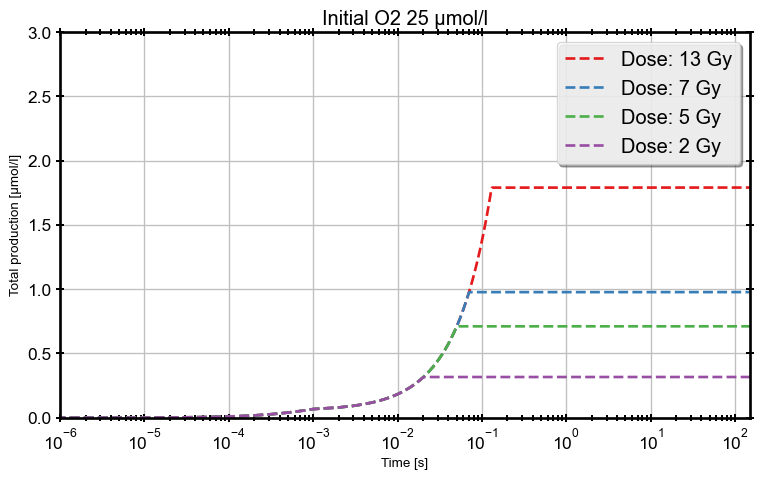

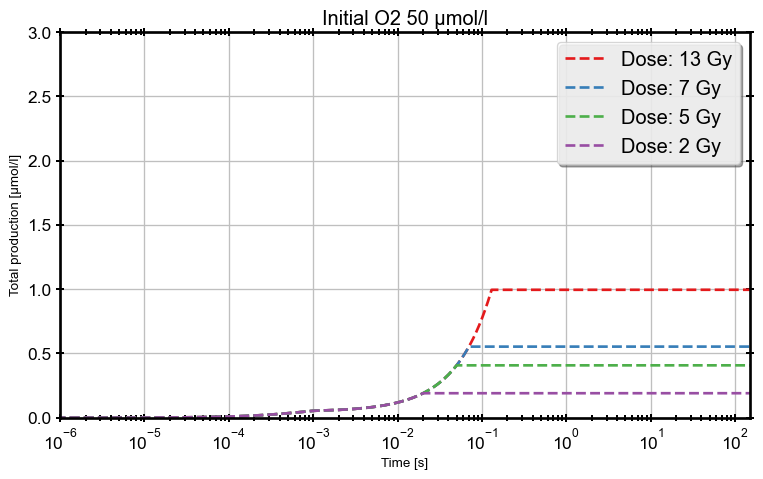

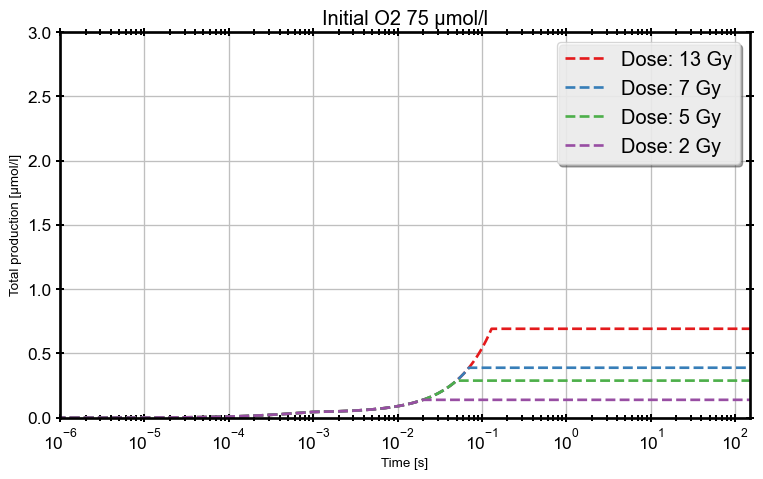

In [97]:
buckets = more_itertools.bucket(filter(lambda x: x.TD<15 and x.DR==1e2, files), key=lambda x: x.O2)
for O2 in buckets:
    with FM.open(f"O2 {O2}") as (fig, ax):
        for data_file in sorted(buckets[O2], key=lambda x: x.TD, reverse=True):
            df = data_file.data
            ax.semilogx(df.index, df["R_r"].cumsum(), label=f"Dose: {data_file.TD:.0f} Gy", marker="")
        ax.legend()
        ax.set_xlim([1e-6, 150])
        ax.set_ylim([0, 3])
        ax.set_title(f"Initial O2 {O2} µmol/l")
        ax.set_xlabel("Time [s]")
        ax.set_ylabel("Total production [µmol/l]")
        if save_folder.exists():
            fig.savefig(save_folder / f"integral_Rr_O2_{O2}.png")

### Species = O2

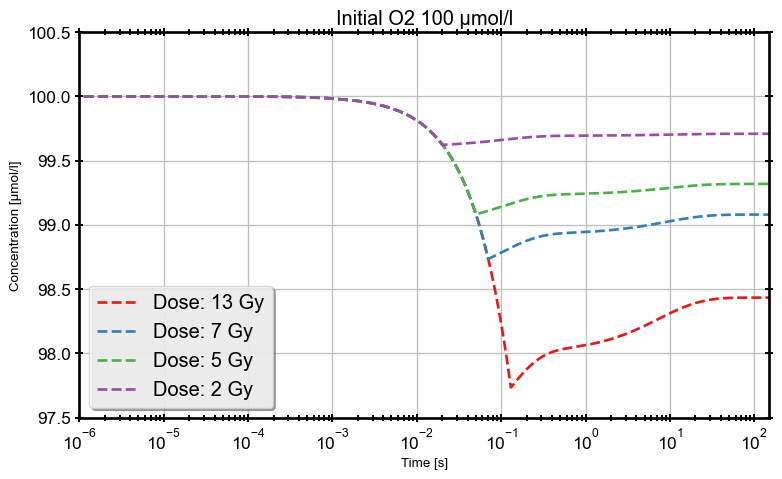

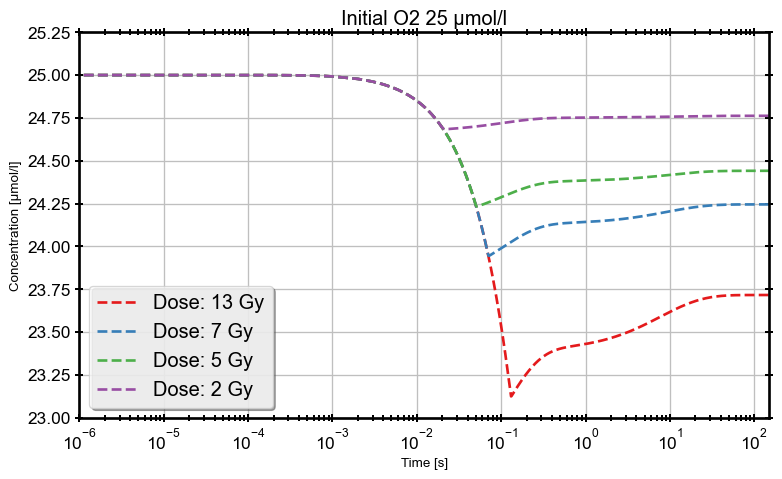

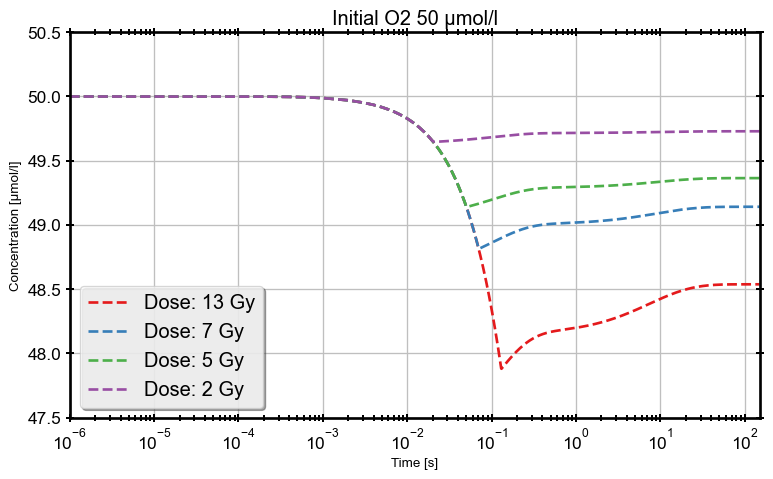

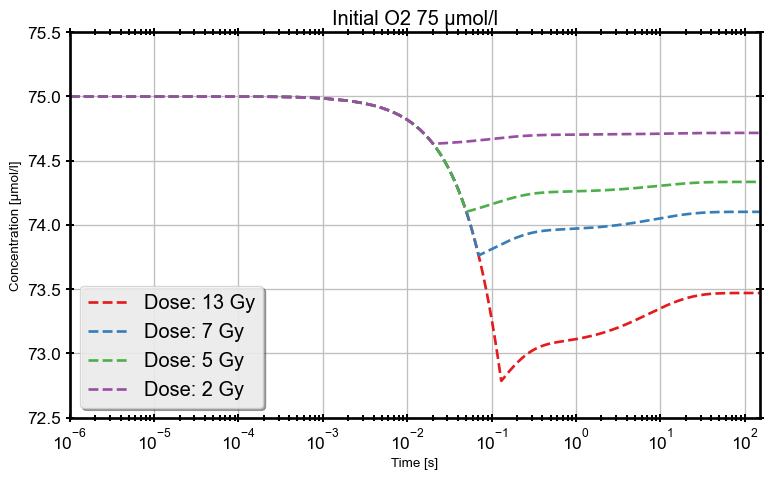

In [84]:
buckets = more_itertools.bucket(filter(lambda x: x.TD<15 and x.DR==1e2, files), key=lambda x: x.O2)
for O2 in buckets:
    with FM.open(f"O2 {O2}") as (fig, ax):
        for data_file in sorted(buckets[O2], key=lambda x: x.TD, reverse=True):
            df = data_file.data
            ax.semilogx(df.index, df["O2"], label=f"Dose: {data_file.TD:.0f} Gy", marker="")
        ax.legend()
        ax.set_xlim([1e-6, 150])
        #ax.set_ylim([1e-6, 10])
        ax.set_title(f"Initial O2 {O2} µmol/l")
        ax.set_xlabel("Time [s]")
        ax.set_ylabel("Concentration [µmol/l]")
        if save_folder.exists():
            fig.savefig(save_folder / f"cc_O2_O2_{O2}.png")

### Species = H2O2

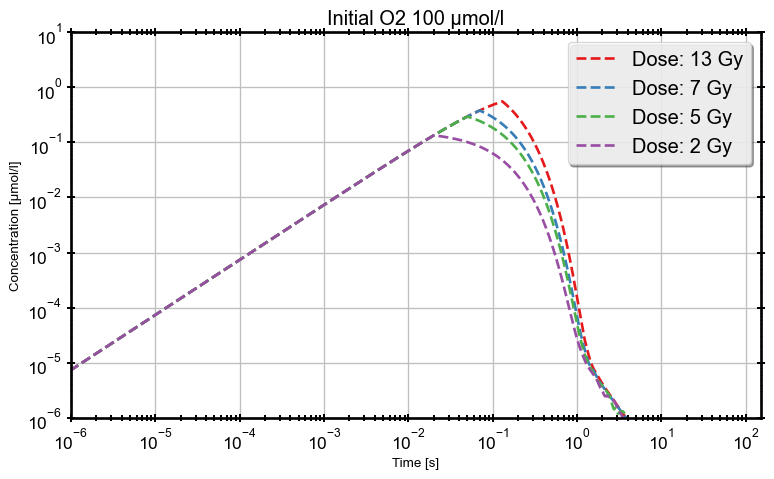

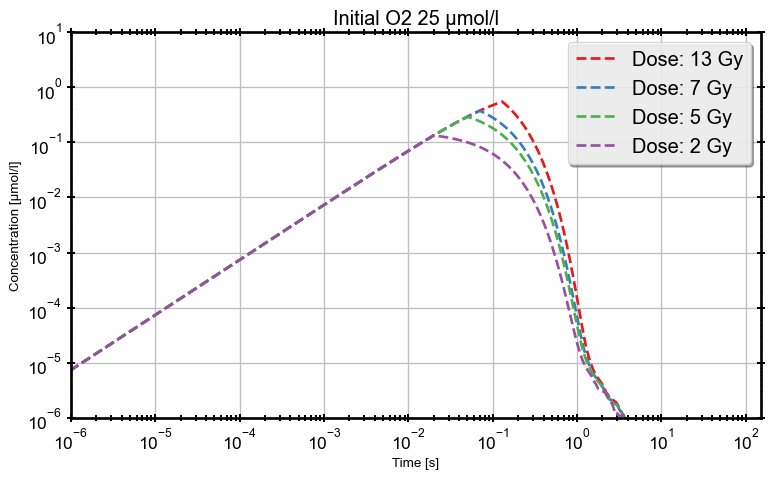

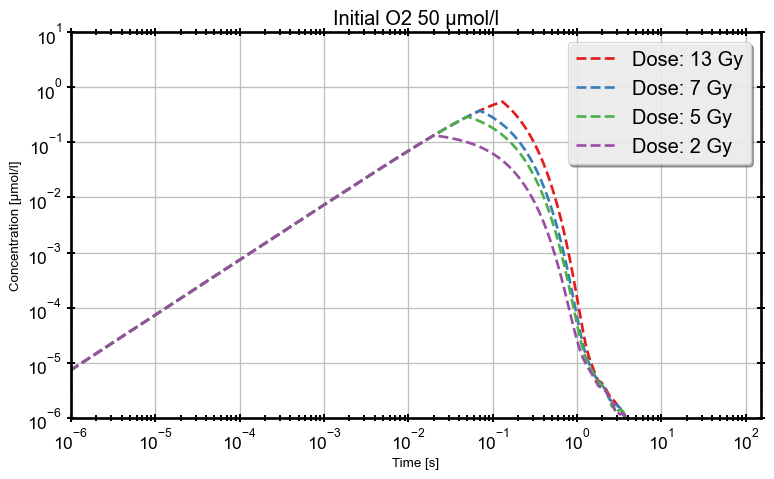

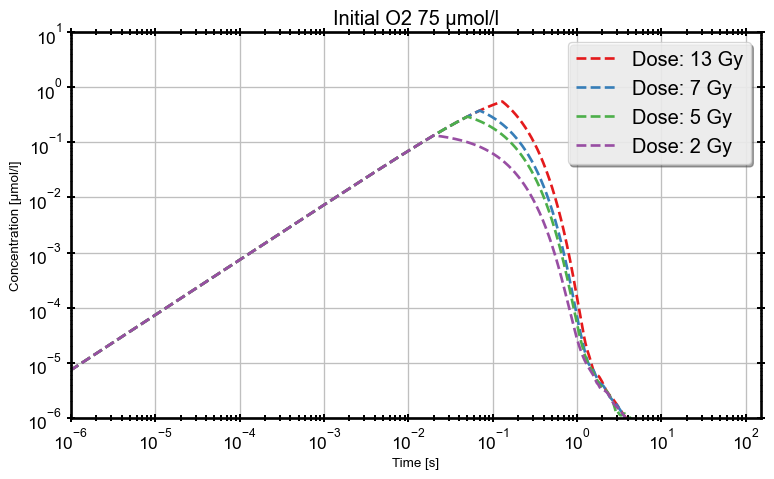

In [85]:
buckets = more_itertools.bucket(filter(lambda x: x.TD<15 and x.DR==1e2, files), key=lambda x: x.O2)
for O2 in buckets:
    with FM.open(f"O2 {O2}") as (fig, ax):
        for data_file in sorted(buckets[O2], key=lambda x: x.TD, reverse=True):
            df = data_file.data
            ax.loglog(df.index, df["H2O2"], label=f"Dose: {data_file.TD:.0f} Gy", marker="")
        ax.legend()
        ax.set_xlim([1e-6, 150])
        ax.set_ylim([1e-6, 10])
        ax.set_title(f"Initial O2 {O2} µmol/l")
        ax.set_xlabel("Time [s]")
        ax.set_ylabel("Concentration [µmol/l]")
        if save_folder.exists():
            fig.savefig(save_folder / f"cc_H2O2_O2_{O2}.png")

### Intergal values

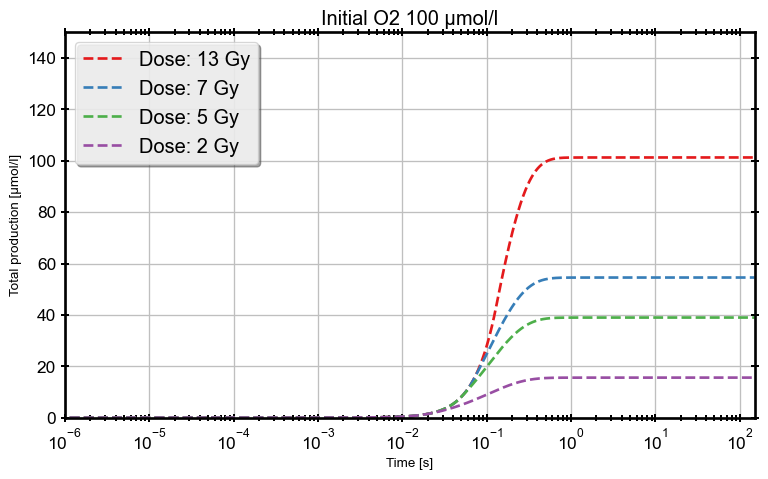

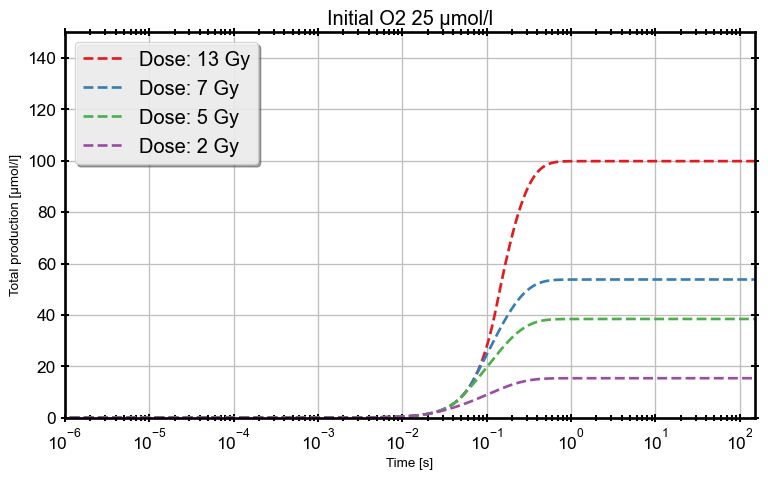

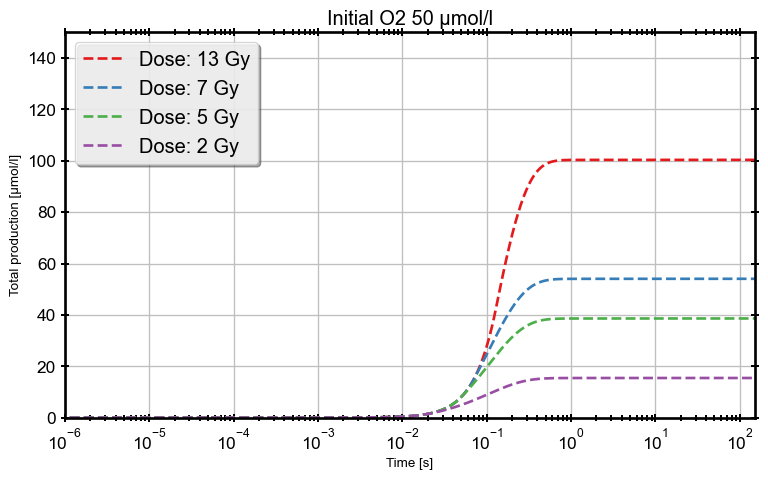

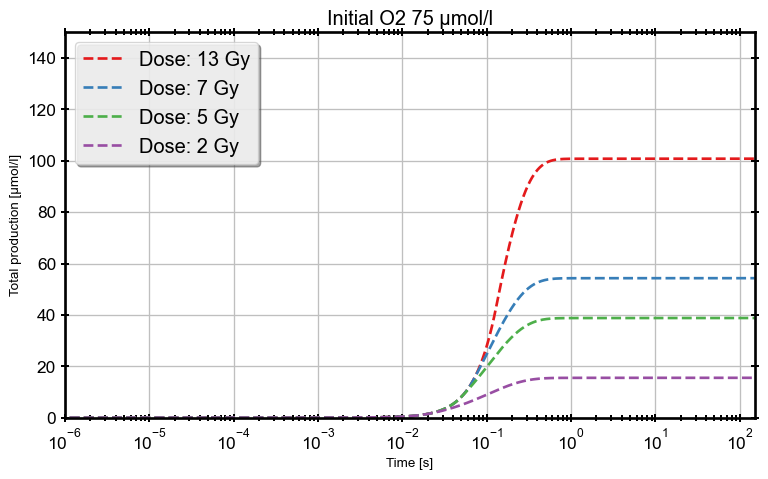

In [86]:
buckets = more_itertools.bucket(filter(lambda x: x.TD<15 and x.DR==1e2, files), key=lambda x: x.O2)
for O2 in buckets:
    with FM.open(f"O2 {O2}") as (fig, ax):
        for data_file in sorted(buckets[O2], key=lambda x: x.TD, reverse=True):
            df = data_file.data
            ax.semilogx(df.index, df["H2O2"].cumsum(), label=f"Dose: {data_file.TD:.0f} Gy", marker="")
        ax.legend()
        ax.set_xlim([1e-6, 150])
        ax.set_ylim([0, 150])
        ax.set_title(f"Initial O2 {O2} µmol/l")
        ax.set_xlabel("Time [s]")
        ax.set_ylabel("Total production [µmol/l]")
        if save_folder.exists():
            fig.savefig(save_folder / f"integral_H2O2_O2_{O2}.png")

## Plot for 100 & 1000 Gy/s

In [100]:
save_folder = Path(r"C:\Users\rtonneau\OneDrive - Université de Namur\Documents\EPT\MEETINGS\20230331\FIGURES\DR_cmp")

### Species = ROO_r

C:\Users\rtonneau\AppData\Local\Temp\ipykernel_4936\3458750020.py:25: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.savefig(save_folder / f"cc_ROOr_O2_{O2}.png")


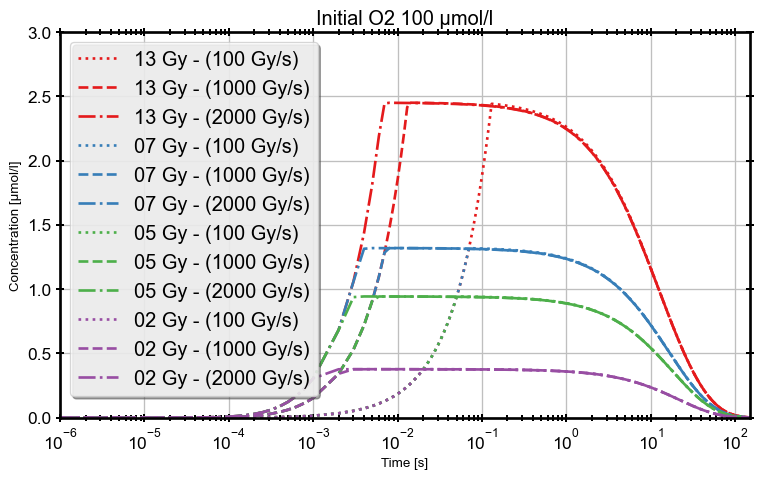

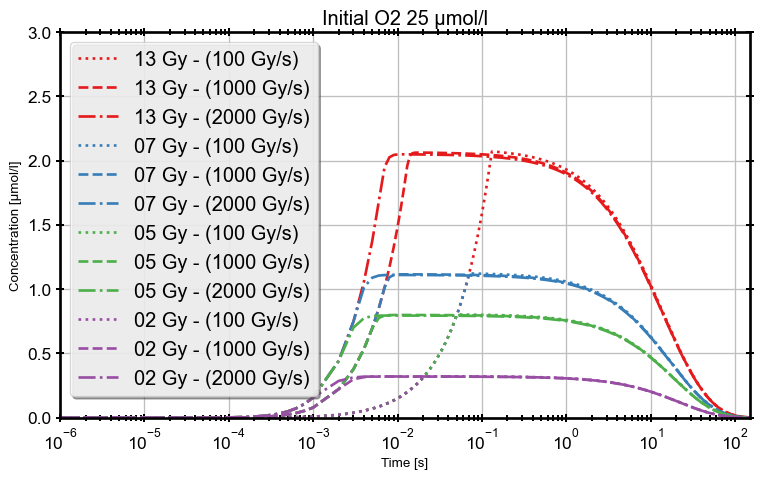

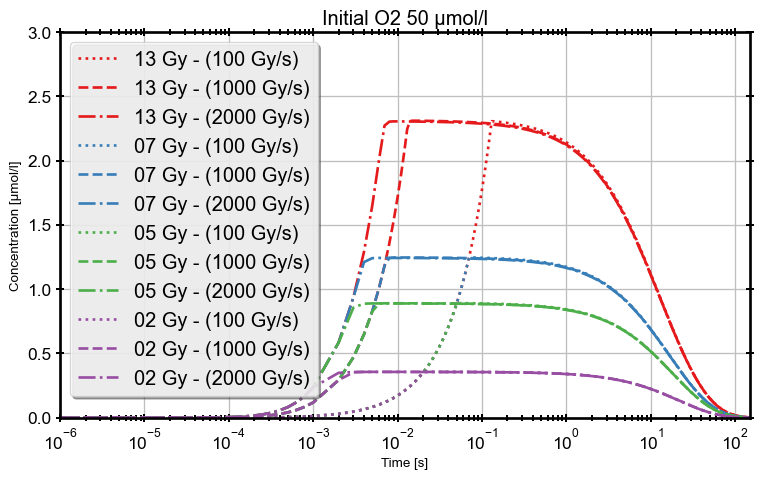

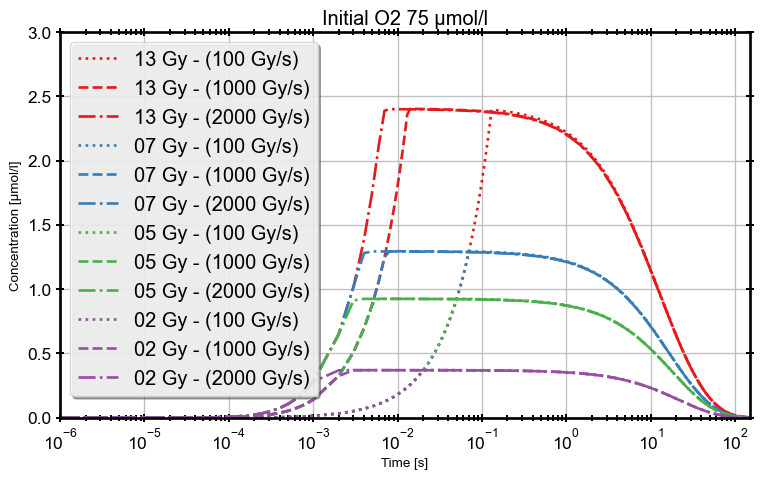

In [113]:
buckets = more_itertools.bucket(filter(lambda x: x.TD<15 and x.DR in [100,1000,2000], files), key=lambda x: x.O2)
for O2 in buckets:
    title = f"O2 {O2}"
    with FM.open(title) as (fig, ax):
        alt, color = 0, ""
        for data_file in sorted(buckets[O2], key=lambda x: x.TD, reverse=True):
            df = data_file.data
            label = f"{data_file.TD:02d} Gy - ({data_file.DR:d} Gy/s)"
            if alt == 0: 
                l, = ax.semilogx(df.index, df["ROO_r"], label=label, marker="", linestyle=":")
                color = l.get_color()
            elif alt == 1:
                l, = ax.semilogx(df.index, df["ROO_r"], label=label, marker="", color=color, linestyle="--")
            else:
                l, = ax.semilogx(df.index, df["ROO_r"], label=label, marker="", color=color, linestyle="-.")
            alt += 1
            alt = alt % 3
        ax.legend()
        ax.set_xlim([1e-6, 150])
        ax.set_ylim([0, 3])
        ax.set_title(f"Initial O2 {O2} µmol/l")
        ax.set_xlabel("Time [s]")
        ax.set_ylabel("Concentration [µmol/l]")
        if save_folder.exists():
            fig.savefig(save_folder / f"cc_ROOr_O2_{O2}.png")